# MSCNN


In [1]:
from pathlib import Path
import re
import subprocess
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

METHOD = 'mscnn'
LABEL = 'MSCNN'



## Data


In [13]:
# Locate the project when running locally.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / 'dehazing' / 'methods').is_dir()), None)
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive')
    WORK = Path('/content/dehaze_upstream')
else:
    BASE_DIR = REPO_ROOT or Path.cwd()
    WORK = BASE_DIR / '.dehaze_upstream'

RESIZE = 1600                 # Maximum long edge. Use 800 for O-HAZE-800.
MAX_IMAGES = None                # Set to None to run every pair.
# SRC = BASE_DIR / 'O-HAZE'     # Original dataset with hazy/ and GT/
SRC = Path(r"C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\O-HAZE")

DATA_ROOT = BASE_DIR / (f'O-HAZE-{RESIZE}' if RESIZE > 0 else 'O-HAZE-native')
OUT = BASE_DIR / 'outputs' / METHOD


In [15]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}


def image_index(folder):
    indexed = {}
    for path in sorted(folder.iterdir()):
        if not path.is_file() or path.suffix.lower() not in IMAGE_SUFFIXES:
            continue
        key = re.sub(r'[_-](?:hazy|gt|clear)$', '', path.stem.lower())
        if key in indexed:
            raise ValueError(f'Duplicate image pair key {key}: {indexed[key]} and {path}')
        indexed[key] = path
    return indexed


def paired_images(root):
    hazy = image_index(root / 'hazy')
    gt = image_index(root / 'GT')
    if not hazy or set(hazy) != set(gt):
        raise ValueError(f'{root}: check hazy/ and GT/ pairing. '
                         f'Missing GT: {sorted(hazy.keys() - gt.keys())}; '
                         f'missing hazy: {sorted(gt.keys() - hazy.keys())}')
    return sorted(((hazy[key], gt[key]) for key in hazy), key=lambda pair: pair[0].name)


def read_rgb(path):
    with Image.open(path) as im:
        return im.convert('RGB')


def save_png(image, path):
    pending = path.with_name('.' + path.name + '.part')
    image.save(pending, format='PNG')
    pending.replace(path)


if all((SRC / name).is_dir() for name in ('hazy', 'GT')):
    if SRC.resolve() == DATA_ROOT.resolve():
        raise ValueError('SRC and DATA_ROOT must be separate folders.')
    for name in ('hazy', 'GT'):
        (DATA_ROOT / name).mkdir(parents=True, exist_ok=True)
    for hazy_file, gt_file in paired_images(SRC):
        hazy_out = DATA_ROOT / 'hazy' / (hazy_file.stem + '.png')
        gt_out = DATA_ROOT / 'GT' / (gt_file.stem + '.png')
        if hazy_out.is_file() and gt_out.is_file():
            continue
        hazy = read_rgb(hazy_file)
        scale = min(1.0, RESIZE / max(hazy.size)) if RESIZE > 0 else 1.0
        size = tuple(max(1, round(v * scale)) for v in hazy.size)
        save_png(hazy.resize(size, Image.Resampling.BICUBIC), hazy_out)
        save_png(read_rgb(gt_file).resize(size, Image.Resampling.BICUBIC), gt_out)
elif not all((DATA_ROOT / name).is_dir() for name in ('hazy', 'GT')):
    raise FileNotFoundError(f'Set SRC to an O-HAZE folder with hazy/ and GT/. Checked: {SRC}')

if MAX_IMAGES is not None and MAX_IMAGES < 1:
    raise ValueError('MAX_IMAGES must be positive or None.')
pairs = paired_images(DATA_ROOT)[:MAX_IMAGES]
for hazy_path, gt_path in pairs:
    with Image.open(hazy_path) as hazy, Image.open(gt_path) as gt:
        if hazy.size != gt.size or (RESIZE > 0 and max(hazy.size) > RESIZE):
            raise ValueError(f'Recreate {DATA_ROOT} at the configured RESIZE. Check {hazy_path.name}.')
OUT.mkdir(parents=True, exist_ok=True)
print(f'{len(pairs)} image(s) | Input: {DATA_ROOT} | Output: {OUT}')


5 image(s) | Input: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\O-HAZE-800 | Output: C:\Users\Lenovo\Desktop\Project in Software Development in Image Analysis and Machine Learning\github\vidhance-extendview\outputs\mscnn


## Pretrained weights
Public weights are downloaded by default. For local weights, set `CHECKPOINT` to the folder containing both `.mat` files.


In [17]:
CHECKPOINT = None             # Or directory containing MSCNNDehazing_CL.mat and MSCNNDehazing_FL.mat.

import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__} | Device: {DEVICE}')

def upstream(repo, revision):
    path = WORK / 'upstream' / (repo.replace('/', '--') + '-' + revision[:8])
    if not (path / '.git').is_dir():
        path.mkdir(parents=True, exist_ok=True)
        subprocess.run(['git', 'init', '-q', str(path)], check=True)
    head = subprocess.run(['git', '-C', str(path), 'rev-parse', 'HEAD'],
                          capture_output=True, text=True).stdout.strip()
    if head != revision:
        try:
            subprocess.run(['git', '-C', str(path), 'fetch', '-q', '--depth', '1',
                            'https://github.com/' + repo + '.git', revision], check=True)
            subprocess.run(['git', '-C', str(path), 'checkout', '-q', '--detach', 'FETCH_HEAD'], check=True)
        except subprocess.CalledProcessError as e:
            raise RuntimeError(f'无法获取 {repo}。请检查 Git 和网络连接。') from e
    return path

def tensor_rgb(img):
    return torch.from_numpy(np.array(img, dtype=np.float32) / 255).permute(2, 0, 1)[None].to(DEVICE)

from scipy.io import loadmat
import scipy.ndimage as ndi

GRAY = np.array([0.298936, 0.587043, 0.114021], dtype=np.float32)
def guided_filter(gray, value, radius, eps):
    def box(a):
        return ndi.uniform_filter(a, 2 * radius + 1, mode='constant')
    count = box(np.ones_like(gray))
    g, v = box(gray) / count, box(value) / count
    cov = box(gray * value) / count - g * v
    var = box(gray * gray) / count - g * g
    slope = cov / (var + eps)
    return box(slope) / count * gray + box(v - slope * g) / count

if CHECKPOINT is None:
    repo = upstream('rwenqi/Multi-scale-CNN-Dehazing', '5075ccf0fddfc36b5d535f181871df29bae2305b')
    model_dir = repo / 'dehazing_code'
else:
    model_dir = Path(CHECKPOINT)
for name in ('MSCNNDehazing_CL.mat', 'MSCNNDehazing_FL.mat'):
    if not (model_dir / name).is_file():
        raise FileNotFoundError(f'Set CHECKPOINT to a folder containing both MSCNN weights. Missing {model_dir / name}')

def mat_network(filename):
    layers = loadmat(model_dir / filename, struct_as_record=False, squeeze_me=True)['net'].layers
    parsed = []
    for layer in layers:
        kind = layer.type
        if kind == 'conv':
            w = torch.tensor(layer.filters.transpose(3, 2, 0, 1).copy(), device=DEVICE, dtype=torch.float32)
            b = torch.tensor(layer.biases, device=DEVICE, dtype=torch.float32)
            parsed.append((kind, (w, b, int(layer.pad[0]), int(layer.stride))))
        elif kind == 'chnLinComb':
            w = torch.tensor(layer.filters, device=DEVICE, dtype=torch.float32)[None, :, None, None]
            parsed.append((kind, (w, float(layer.biases))))
        else:
            parsed.append((kind, getattr(layer, 'param', None)))
    return parsed
coarse = mat_network('MSCNNDehazing_CL.mat')
fine = mat_network('MSCNNDehazing_FL.mat')



PyTorch 2.8.0+cpu | Device: cpu


## Model


In [19]:
def run_layers(x, layers, coarse_map=None):
    for i, (kind, args) in enumerate(layers):
        if kind == 'conv':
            w, b, pad, stride = args
            x = F.conv2d(x, w, b, stride=stride, padding=pad)
            if i == 0 and coarse_map is not None:
                coarse_resized = F.interpolate(coarse_map, size=x.shape[-2:], mode='bicubic', align_corners=False)
                x = torch.cat((x[:, :5], coarse_resized), dim=1)
        elif kind == 'relu':
            x = x.relu()
        elif kind == 'pool':
            x = F.max_pool2d(x, 2, 2)
        elif kind == 'upsmpl':
            x = F.interpolate(x, scale_factor=2, mode='nearest')
        elif kind == 'normalize':
            size, k, alpha, beta = args
            x = F.local_response_norm(x, int(size), alpha=float(alpha * size), beta=float(beta), k=float(k))
        elif kind == 'chnLinComb':
            w, b = args
            x = ((x * w).sum(dim=1, keepdim=True) + b).sigmoid()
        else:
            raise ValueError(f'Unknown MatConvNet layer: {kind}')
    return x



## Method


In [21]:
def dehaze(hazy):
    x = tensor_rgb(hazy)
    im = np.asarray(hazy, dtype=np.float32) / 255
    air = ndi.minimum_filter(im, size=(15, 15, 1), mode='reflect').max(axis=(0, 1))
    balanced = x / torch.as_tensor(air.clip(1e-6), device=x.device)[None, :, None, None]
    t = run_layers(balanced, fine, run_layers(balanced, coarse))
    t = F.interpolate(t, size=x.shape[-2:], mode='bicubic', align_corners=False)[0, 0].cpu().numpy()
    gray = im @ GRAY
    beta = (gray - air @ GRAY) ** 2
    inv = (beta + 0.1 / np.maximum(t, 1e-6)) / (beta + 0.1)
    inv = guided_filter(gray, inv, min(gray.shape) // 8, 0.04)
    t = (1 / np.maximum(inv, 1e-6)).clip(0.1, 0.9)
    return (im - air) / t[..., None] + air


## Run over the dataset


In [27]:
for hazy_path, _ in pairs:
    hazy = read_rgb(hazy_path)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t0 = perf_counter()
        prediction = dehaze(hazy)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        elapsed_ms = (perf_counter() - t0) * 1000
    if prediction.shape != (hazy.height, hazy.width, 3) or not np.isfinite(prediction).all():
        raise ValueError(f'{LABEL}: invalid RGB prediction for {hazy_path.name} ({prediction.shape}).')
    output = Image.fromarray(np.rint(np.clip(prediction, 0, 1) * 255).astype(np.uint8))
    target = OUT / hazy_path.name
    pending = target.with_name('.' + target.stem + '.part' + target.suffix)
    output.save(pending)
    pending.replace(target)
    print(f'{hazy_path.name} | {hazy.width}x{hazy.height} | {elapsed_ms:.1f} ms')


01_outdoor_hazy.png | 741x800 | 959.3 ms
02_outdoor_hazy.png | 641x800 | 718.7 ms
03_outdoor_hazy.png | 800x533 | 650.9 ms
04_outdoor_hazy.png | 663x800 | 763.1 ms
05_outdoor_hazy.png | 800x632 | 751.8 ms


## Preview


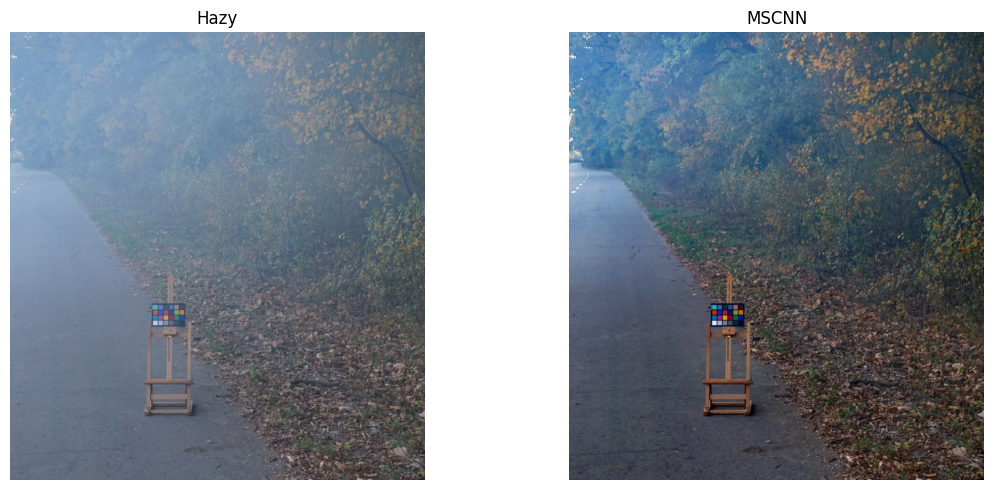

In [29]:
hazy_path, _ = pairs[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, path, title in zip(axes, (hazy_path, OUT / hazy_path.name), ('Hazy', LABEL)):
    ax.imshow(read_rgb(path))
    ax.set_title(title)
    ax.axis('off')
fig.tight_layout()
plt.show()
